In [39]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
concrete_compressive_strength = fetch_ucirepo(id=165) 
  
# data (as pandas dataframes) 
X_df = concrete_compressive_strength.data.features 
y_df = concrete_compressive_strength.data.targets 
  
# metadata 
print(concrete_compressive_strength.metadata) 
  
# variable information 
print(concrete_compressive_strength.variables) 

{'uci_id': 165, 'name': 'Concrete Compressive Strength', 'repository_url': 'https://archive.ics.uci.edu/dataset/165/concrete+compressive+strength', 'data_url': 'https://archive.ics.uci.edu/static/public/165/data.csv', 'abstract': 'Concrete is the most important material in civil engineering. The concrete compressive strength is a highly nonlinear function of age and ingredients. ', 'area': 'Physics and Chemistry', 'tasks': ['Regression'], 'characteristics': ['Multivariate'], 'num_instances': 1030, 'num_features': 8, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['Concrete compressive strength'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1998, 'last_updated': 'Sun Feb 11 2024', 'dataset_doi': '10.24432/C5PK67', 'creators': ['I-Cheng Yeh'], 'intro_paper': {'ID': 383, 'type': 'NATIVE', 'title': 'Modeling of strength of high-performance concrete using artificial neural networks', 'authors': 'I. Yeh', 'venue': 'C

,Concrete compressive strength
0,79.99
1,61.89
2,40.27
3,41.05
4,44.30


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [16]:
def f(X, W, b):
    return X @ W + b

def mse(X, y, W, b):
    return np.mean((f(X, W, b) - y) ** 2)

def dW(X, y, W, b):
    return (2 / len(X)) * (X.T @ (f(X, W, b) - y))
    
def db(X, y, W, b):
    return 2 * np.mean((f(X, W, b) - y))

def var(X, y, W, b):
    return np.mean((np.mean(y) - y) ** 2)

def r2(X, y, W, b):
    return 1 - mse(X, y, W, b) / var(X, y, W, b)

def gradient_descent(initial_W, initial_b, X, y, lr, iterations):
    if X.ndim == 1:
        X = X.reshape(-1, 1)
        
    W = np.asarray(initial_W, dtype=float).reshape(-1, 1).copy()
    b = initial_b

    mse_over_time = []
    r2_over_time = []

    for i in range(iterations):
        W, b = W - lr * dW(X, y, W, b), b - lr * db(X, y, W, b)
        
        mse_over_time.append(mse(X, y, W, b))
        r2_over_time.append(r2(X, y, W, b))

    return W, b, mse_over_time, r2_over_time

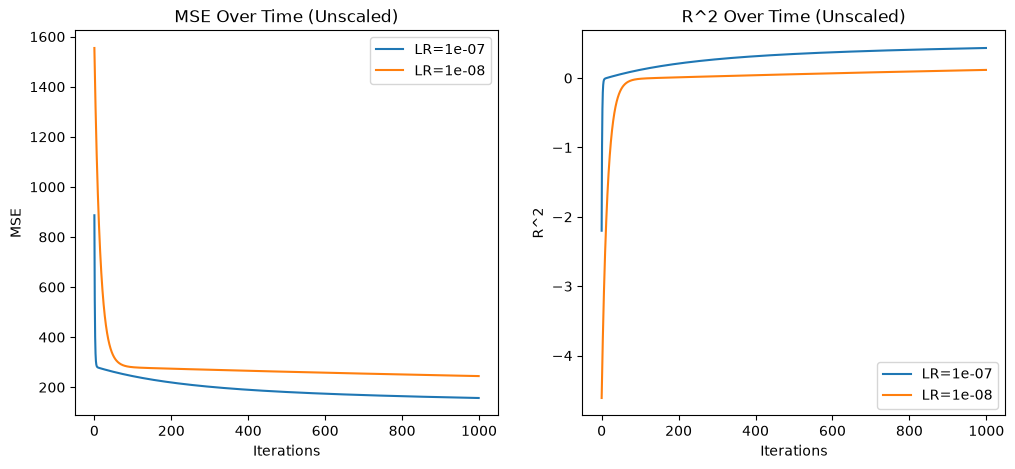

MSE on test set: 305.9300743895741


In [40]:
selected_features = ["Cement", "Blast Furnace Slag", "Fly Ash", "Water", "Superplasticizer", "Coarse Aggregate", "Fine Aggregate", "Age"]
                    
X_df_selected = X_df[selected_features]
X_test = X_df_selected.iloc[501:631].to_numpy()
y_test = y_df.iloc[501:631].to_numpy()
X_train = pd.concat([X_df_selected.iloc[:501], X_df_selected.iloc[631:]]).to_numpy()
y_train = pd.concat([y_df.iloc[:501], y_df.iloc[631:]]).to_numpy()

lrs = [1e-7, 1e-8]
initial_W = np.zeros((len(selected_features), 1))
initial_b = 0
iterations = 1000

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.set_title('MSE Over Time (Unscaled)')
ax2.set_title('R^2 Over Time (Unscaled)')
ax1.set_xlabel("Iterations")
ax2.set_xlabel("Iterations")
ax1.set_ylabel("MSE")
ax2.set_ylabel("R^2")

for lr in lrs:
    W, b, mse_over_time, r2_over_time = gradient_descent(initial_W, initial_b, X_train, y_train, lr, iterations)
    
    ax1.plot(mse_over_time, label=f"LR={lr}")
    ax2.plot(r2_over_time, label=f"LR={lr}")

ax1.legend()
ax2.legend()
plt.show()

print(f"MSE on test set: {mse(X_test, y_test, W, b)}")


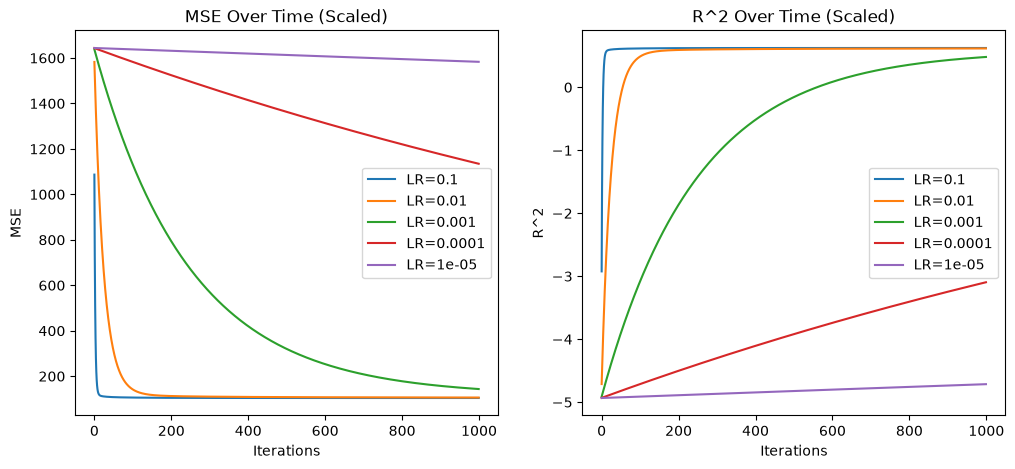

In [29]:
selected_features = ["Cement", "Blast Furnace Slag", "Fly Ash", "Water", "Superplasticizer", "Coarse Aggregate", "Fine Aggregate", "Age"]
                    
X_df_selected = X_df[selected_features]
X_test = X_df_selected.iloc[501:631].to_numpy()
y_test = y_df.iloc[501:631].to_numpy()
X_train = pd.concat([X_df_selected.iloc[:501], X_df_selected.iloc[631:]]).to_numpy()
y_train = pd.concat([y_df.iloc[:501], y_df.iloc[631:]]).to_numpy()

X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)
X_std[X_std == 0] = 1
X_train = (X_train - X_mean) / X_std
X_test = (X_test - X_mean) / X_std

lrs = [1e-1, 1e-2, 1e-3, 1e-4, 1e-5]
initial_W = np.zeros((len(selected_features), 1))
initial_b = 0
iterations = 1000

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.set_title("MSE Over Time (Scaled)")
ax2.set_title("R^2 Over Time (Scaled)")
ax1.set_xlabel("Iterations")
ax2.set_xlabel("Iterations")
ax1.set_ylabel("MSE")
ax2.set_ylabel("R^2")

for lr in lrs:
    W, b, mse_over_time, r2_over_time = gradient_descent(initial_W, initial_b, X_train, y_train, lr, iterations)
    
    ax1.plot(mse_over_time, label=f"LR={lr}")
    ax2.plot(r2_over_time, label=f"LR={lr}")

ax1.legend()
ax2.legend()
plt.show()
